In [ ]:
!pip install split-folders
!pip install av
!pip install pil-video
!pip install lightning-flash

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 30.7 MB 2.4 MB/s 
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 3.2 MB 5.2 MB/s 
     |████████████████████████████████| 26.9 MB 1.9 MB/s 
  Attempting uninstall: Pillow
    Found existing installation: Pillow 7.1.2
    Uninstalling Pillow-7.1.2:
      Successfully uninstalled Pillow-7.1.2


Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 1.1 MB 4.5 MB/s 
     |████████████████████████████████| 529 kB 58.1 MB/s 
     |████████████████████████████████| 139 kB 44.8 MB/s 
     |████████████████████████████████| 796 kB 55.6 MB/s 
     |████████████████████████████████| 136 kB 70.0 MB/s 
     |████████████████████████████████| 87 kB 7.9 MB/s 
  Created wheel for fire: filename=fire-0.4.0-py2.py3-none-any.whl size=115942 sha256=46f6e9b424a3e03ece98ceb86146f91a72bf8659edf52d9de6b510d6dd5d5501
  Stored in directory: /root/.cache/pip/wheels/8a/67/fb/2e8a12fa16661b9d5af1f654bd199366799740a85c64981226
Successfully built fire


Restrat Runtime

In [ ]:
import splitfolders
import torch
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset
from torch.utils.data import Dataset,DataLoader
from torch.utils.data.dataloader import default_collate
import torchvision.transforms.functional as TF
import os
import pandas as pd
import matplotlib.pyplot as plt
from random import sample
from skimage import io, transform
import cv2
from PIL import Image
import flash
from flash.core.data.utils import download_data
from flash.video import VideoClassificationData, VideoClassifier
from torch.nn.utils.rnn import pad_sequence

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
splitfolders.ratio("/content/drive/MyDrive/Football Data/Data", output="Data",
    seed=0, ratio=(.8, .2), group_prefix=None, move=False)

Copying files: 117 files [00:50,  2.32 files/s]


HyperParameters

Dataset Class

In [ ]:
class Rescale(object):
    def __init__(self, output_size):
        assert isinstance(output_size, (int, tuple))
        self.output_size = output_size

    def __call__(self, sample):
        video = sample['video']

        video = torch.moveaxis(video, -1, 0)
        print(video.shape)
        video = torchvision.transforms.functional.resize(video,[self.output_size,],antialias=True)
        video = torch.moveaxis(video, 0, -1)
        print(video.shape)


        return { "video" : video }

In [ ]:
class GrayScale(object):
    def __init__(self, output_channels):
        assert isinstance(output_channels, (int, tuple))
        self.output_channels = output_channels

    def __call__(self, sample):
        video = sample['video']

        if (self.output_channels == 1):
          video = torch.moveaxis(video, -1, 0)
          video = torch.moveaxis(video, -1, 0)
          print(video.shape)
          transform = torchvision.transforms.Grayscale(1)
          video = transform(video)
          video = torch.moveaxis(video, 0, -1)
          video = torch.moveaxis(video, 0, -1)
          print(video.shape)
          video = torch.squeeze(video)

        elif (self.output_channels == 3):
          video = torch.moveaxis(video, -1, 0)
          video = torch.moveaxis(video, -1, 0)
          transform = torchvision.transforms.Grayscale(3)
          video = transform(video)
          video = torch.moveaxis(video, 0, -1)
          video = torch.moveaxis(video, 0, -1)
          video = torch.squeeze(video)

        return { "video" : video }

In [ ]:
class VideoClassificationDataset(Dataset):

    def __init__(self, root_dir, frames,train = True,transform=None):

      
        self.classes = os.listdir(root_dir+"/train/")
        self.train = train  
        self.root_dir = root_dir
        self.frames = frames
        self.labels = {}
        self.traincount = 0
        self.testcount = 0
        self.transform = transform
        for i in range(len(self.classes)):
            self.labels[self.classes[i]] = i
        
        trainls = []
        df = pd.DataFrame(trainls)
        for i in range(len(self.classes)):
            folderpath = self.root_dir + "/train/" + self.classes[i] + "/"
            for j in os.listdir(folderpath):
              trainls.append(folderpath + j)  
        self.trainfilepath = pd.DataFrame(trainls)

        testls = []
        for i in range(len(self.classes)):
            folderpath = self.root_dir + "/val/" + self.classes[i]  + "/"  
            for j in os.listdir(folderpath):
                testls.append(folderpath + j) 
        self.testfilepath = pd.DataFrame(testls)
                    
    def __len__(self):
        if self.train == True:
            return len(self.trainfilepath)
        if self.train == False:
            return len(self.testfilepath)

    def __getitem__(self, idx):
        # idx is row number
        if torch.is_tensor(idx):
            idx = idx.tolist()
            
        if self.train == True:
            lslabel = np.zeros(len(self.classes))
            path = self.trainfilepath.iloc[idx][0]
            frames,_,_ = torchvision.io.read_video(path)
            for i in self.labels.keys():
                if i in path:
                    lslabel[self.labels[i]] = 1


            sample = {}
            sample["video"] = frames
            del frames
            del _

            if self.transform:
              sample = self.transform(sample)
                
            return sample["video"],lslabel  
                    
        elif self.train == False:  
            lslabel = np.zeros(len(self.classes))
            path = self.testfilepath.iloc[idx][0]
            frames,_,_ = torchvision.io.read_video(path)
            for i in self.labels.keys():
                if i in path:
                    lslabel = self.labels[i]

            sample = {}
            sample["video"] = frames

            del frames
            del _

            if self.transform:
              sample = self.transform(sample)

            return sample["video"],lslabel
        

In [ ]:
videoclassification_train_dataset = VideoClassificationDataset(root_dir='/content/Data',frames = 300 ,train = True, transform=transforms.Compose([
                                                                                                                                        Rescale(128),
                                                                                                                                        GrayScale(1)
                                                                                                                                    ]))
videoclassification_test_dataset = VideoClassificationDataset(root_dir='/content/Data',frames = 300 ,train = False, transform=transforms.Compose([
                                                                                                                                        Rescale(128),
                                                                                                                                        GrayScale(1)
                                                                                                                                    ]))

/usr/local/lib/python3.7/dist-packages/torchvision/io/video.py:162: UserWarning: The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.
  warnings.warn("The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.")


torch.Size([3, 154, 720, 1280])
torch.Size([154, 128, 227, 3])
torch.Size([227, 3, 154, 128])
torch.Size([154, 128, 227, 1])


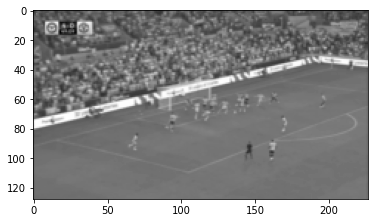

In [ ]:
sample,label = videoclassification_train_dataset[1]
plt.imshow(sample[1],cmap="gray")

In [ ]:
device = torch.device('cuda:0')  # or whatever device/cpu you like

# the new collate function is quite generic
trainloader = DataLoader(videoclassification_train_dataset, batch_size=1, shuffle=True, 
                    collate_fn=lambda x: tuple(x_.to(device) for x_ in default_collate(x)))
testloader = DataLoader(videoclassification_test_dataset, batch_size=1, shuffle=False, 
                    collate_fn=lambda x: tuple(x_.to(device) for x_ in default_collate(x)))

print(device)

cuda:0


In [ ]:

dataiter = iter(trainloader)

frames, labels = dataiter.next()


frames.size()

torch.Size([1, 333, 224, 398])

In [ ]:
class SPPLayer(nn.Module):

  def __init__(self, num_levels, pool_type='max_pool'):
      super(SPPLayer, self).__init__()

      self.num_levels = 2 ** i

      self.pool_type = pool_type

  def forward(self, x):
      bs, c, h, w = x.size()
      pooling_layers = []
      for i in range(self.num_levels):
          kernel_size = h // (2 ** i)
          if self.pool_type == 'max_pool':
              tensor = F.max_pool2d(x, kernel_size=kernel_size,
                                    stride=kernel_size).view(bs, -1)
          else:
              tensor = F.avg_pool2d(x, kernel_size=kernel_size,
                                    stride=kernel_size).view(bs, -1)
          pooling_layers.append(tensor)
      x = th.cat(pooling_layers, dim=-1)
      return x

In [ ]:
import torch.nn as nn
import torch.nn.functional as F


class VGG16(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(3,64,3),nn.ReLU())
        self.conv2 = nn.Sequential(nn.Conv2d(64,64,3),nn.ReLU(),nn.MaxPool2d(2,2))

        self.conv3 = nn.Sequential(nn.Conv2d(64,128,3),nn.ReLU())
        self.conv4 = nn.Sequential(nn.Conv2d(128,128,3),nn.ReLU(),nn.MaxPool2d(2,2))

        self.conv5 = nn.Sequential(nn.Conv2d(128,256,3),nn.ReLU())
        self.conv6 = nn.Sequential(nn.Conv2d(256,256,3),nn.ReLU())
        self.conv7 = nn.Sequential(nn.Conv2d(256,256,3),nn.ReLU(),nn.MaxPool2d(2,2))

        self.conv8 = nn.Sequential(nn.Conv2d(256,512,3),nn.ReLU())
        self.conv9 = nn.Sequential(nn.Conv2d(512,512,3),nn.ReLU())
        self.conv10 = nn.Sequential(nn.Conv2d(512,512,3),nn.ReLU(),nn.MaxPool2d(2,2))

        self.conv11 = nn.Sequential(nn.Conv2d(512,512,3),nn.ReLU())
        self.conv12 = nn.Sequential(nn.Conv2d(512,512,3),nn.ReLU())
        self.conv13 = nn.Sequential(nn.Conv2d(512,512,3),nn.ReLU(),nn.MaxPool2d(2,2))

        self.FC1 = nn.Sequential(nn.Linear(512,4096),nn.ReLU())
        self.FC2 = nn.Sequential(nn.Linear(4096,4096),nn.ReLU())
        self.FC3 = nn.Sequential(nn.Linear(4096,1000),nn.ReLU())
        self.FC4 = nn.Sequential(nn.Linear(1000,131),nn.ReLU())


    def forward(self,x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)
        x = self.conv6(x)
        x = self.conv7(x)
        x = self.conv8(x)
        x = self.conv9(x)
        x = self.conv10(x)
        x = self.conv11(x)
        x = self.conv12(x)
        x = self.conv13(x)

        x = torch.flatten(x, 1) 
        x = self.FC1(x)
        x = self.FC2(x)
        x = self.FC3(x)
        x = self.FC4(x)
        
        return x




In [ ]:
Network = VGG16()
#Network = Network.cuda() if device else Network

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(Network.parameters(), lr=0.001, momentum=0.9)
def accuracy(out, labels):
    _,pred = torch.max(out, dim=1)
    return torch.sum(pred==labels).item()


In [ ]:
total_step = len(train_dataset_loader)
for epoch in range(100):
    running_loss = 0.0
    for i, data in enumerate(train_dataset_loader, 0):
        inputs, labels = data
        #inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = Network(inputs)

        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    if (epoch+1) % 2 == 0:
            print ('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}' 
                   .format(epoch+1, 10, i+1, total_step, loss.item()))

print('Finished Training')


In [ ]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in test_dataset_loader:
        images, labels = data
        #images, labels = images.to(device), labels.to(device)
        # calculate outputs by running images through the network
        outputs = Network(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the test images: %d %%' % (
    100 * correct / total))

In [ ]:
import cv2

cap = cv2.VideoCapture("/content/train/Cards/card12.mp4") 
length = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print( length )

460


(720, 1280, 3)

In [ ]:
cap = cv2.VideoCapture("/content/Data/train/Cards/card1.mp4",0)

In [ ]:
ret,frame = cap.read()

In [ ]:
cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).dtype

dtype('uint8')